In [1]:
# Import libraries for K-Means clustering, scaling, and visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Load the Iris dataset.
df = pd.read_csv("Iris.csv")

In [3]:
# Preview the first five dataset records.
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
# Select flower measurements and exclude ID and species columns.
# Exclude the ID and known species label; clustering uses only flower measurements.
X = df.drop(["Id", "Species"], axis=1)

In [8]:
# Standardize the flower measurements.
scaler = StandardScaler()
# Learn the mean and standard deviation of each feature, then standardize it.
X_scaled = scaler.fit_transform(X)

In [14]:
# Calculate K-Means inertia for cluster counts from 1 to 10.
inertia = []

# Test cluster counts from 1 up to and including 10.
for k in range(1,11):
    # Run K-Means 10 times with different initial centers and keep the best result.
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    # Assign each flower to a cluster and calculate the cluster centers.
    kmeans.fit(X_scaled)
    # Inertia is the within-cluster sum of squared distances; smaller means tighter clusters.
    inertia.append(kmeans.inertia_)

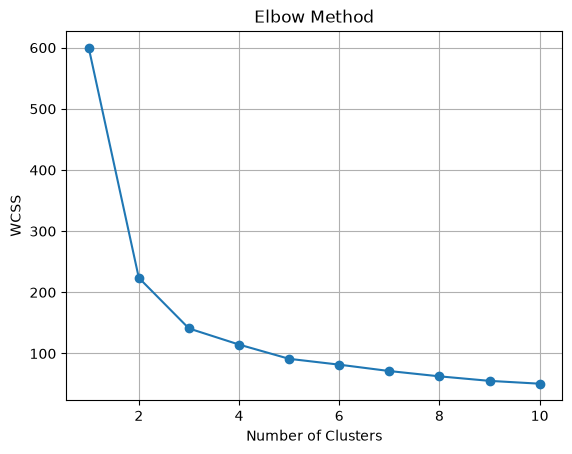

In [15]:
# Plot the elbow graph to help choose the number of clusters.
# Use cluster counts 1 through 10 on the graph.
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()